# UCI Cleveland Heart Disease: Multi-Class Model Training (WITH SMOTE)
## Phase 2: Simple Multi-Class Model Training & Comprehensive Evaluation

### Methodology & Configuration:
1. **Dataset**: UCI Cleveland Heart Disease (303 patient records, 13 clinical features).
2. **Task**: Multi-class coronary artery disease (CAD) severity classification across **5 clinical severity classes**:
   - `Class 0`: No CAD (<50% stenosis)
   - `Class 1`: Mild CAD
   - `Class 2`: Moderate CAD
   - `Class 3`: Severe CAD
   - `Class 4`: Critical CAD (Multi-vessel)
3. **Balancing Strategy**: **Multi-Class SMOTE (k=3)** applied **strictly to the training split** to synthesize minority class samples and achieve 131 samples per class (total 655 samples). The holdout test set remains pristine (61 samples).
4. **Classifiers Evaluated**:
   - **Logistic Regression (LR)**: Multinomial One-vs-Rest linear baseline
   - **Support Vector Machine (SVM)**: RBF kernel with probability calibration
   - **Random Forest (RF)**: 100 decision trees ensemble
   - **Lightweight Neural Network (LNN)**: 3-layer MLP (128 -> 64 -> 32) with ReLU activation and Early Stopping
5. **Evaluation Protocol**:
   - Evaluated on holdout test set using **Accuracy, Precision, Recall, F1-Score, and ROC-AUC (One-vs-Rest)**
   - Per-class classification reports across all 5 severity tiers
   - 5x5 normalized confusion matrix heatmaps
   - Multi-class ROC curves per class

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE

# Styling
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.edgecolor'] = '#cccccc'

## 1. Data Ingestion & Schema Mapping
Loading raw Cleveland data with 14 clinical column names and parsing missing indicators.

In [2]:
COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

data_path = 'datasets/heart+disease/processed.cleveland.data'
df = pd.read_csv(data_path, header=None, names=COLUMNS, na_values='?')

print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print("Target class distribution (severity grades 0 to 4):")
print(df['target'].value_counts().sort_index().to_dict())
df.head()

Loaded dataset: 303 rows, 14 columns
Target class distribution (severity grades 0 to 4):
{0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Zero-Leakage Preprocessing Pipeline

1. **Stratified Split**: 80% train / 20% holdout test.
2. **Median & Mode Imputation**: Fitted on `X_train`, applied to `X_train` and `X_test`.
3. **One-Hot Encoding**: Nominal columns (`cp`, `restecg`, `slope`, `thal`) expanded from 13 to 22 dimensions.
4. **Min-Max Normalization**: Scaled to [0, 1] fitted on `X_train`.
5. **SMOTE Balancing**: Multi-Class SMOTE ($k=3$) applied strictly to the training split.

In [3]:
# 1. Feature-Target Separation & Stratified 80/20 Split
X = df.drop(columns=['target'])
y = df['target'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
cat_cols = ['cp', 'restecg', 'slope', 'thal']
bin_cols = ['sex', 'fbs', 'exang']

# 2. Leak-Free Imputation
num_imp = SimpleImputer(strategy='median')
cat_imp = SimpleImputer(strategy='most_frequent')

X_tr_num = pd.DataFrame(num_imp.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_te_num = pd.DataFrame(num_imp.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

X_tr_cat_all = pd.DataFrame(cat_imp.fit_transform(X_train[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_train.index)
X_te_cat_all = pd.DataFrame(cat_imp.transform(X_test[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_test.index)

# 3. One-Hot Encoding for Nominal Attributes
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_cols = ohe.fit(X_tr_cat_all[cat_cols]).get_feature_names_out(cat_cols)

X_tr_ohe = pd.DataFrame(ohe.transform(X_tr_cat_all[cat_cols]), columns=ohe_cols, index=X_train.index)
X_te_ohe = pd.DataFrame(ohe.transform(X_te_cat_all[cat_cols]), columns=ohe_cols, index=X_test.index)

X_tr_full = pd.concat([X_tr_num, X_tr_cat_all[bin_cols], X_tr_ohe], axis=1)
X_te_full = pd.concat([X_te_num, X_te_cat_all[bin_cols], X_te_ohe], axis=1)

# 4. Normalization via MinMaxScaler to [0, 1]
scaler = MinMaxScaler()
feature_names = X_tr_full.columns
X_tr_scaled = pd.DataFrame(scaler.fit_transform(X_tr_full), columns=feature_names, index=X_train.index)
X_te_scaled = pd.DataFrame(scaler.transform(X_te_full), columns=feature_names, index=X_test.index)

# 5. Multi-Class SMOTE (Train Set Only)
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_final, y_train_final = smote.fit_resample(X_tr_scaled, y_train)
X_train_final = pd.DataFrame(X_train_final, columns=feature_names)
y_train_final = pd.Series(y_train_final, name='target')
X_test_final = X_te_scaled
y_test_final = y_test

print('=== PREPROCESSING FINISHED (WITH SMOTE) ===')
print(f'Train shape post-SMOTE: {X_train_final.shape} | Classes: {y_train_final.value_counts().sort_index().to_dict()}')
print(f'Test shape (untouched):  {X_test_final.shape}  | Classes: {y_test_final.value_counts().sort_index().to_dict()}')


=== PREPROCESSING FINISHED (WITH SMOTE) ===
Train shape post-SMOTE: (655, 22) | Classes: {0: 131, 1: 131, 2: 131, 3: 131, 4: 131}
Test shape (untouched):  (61, 22)  | Classes: {0: 33, 1: 11, 2: 7, 3: 7, 4: 3}


## 3. Model Initialization

We define the 4 target classification models:
1. **Logistic Regression (LR)**
2. **Support Vector Machine (SVM)** with RBF kernel and probability estimation
3. **Random Forest (RF)** with 100 estimators
4. **Lightweight Neural Network (LNN)** implemented as a 3-layer `MLPClassifier` (128 -> 64 -> 32) with ReLU activation, Adam optimizer, and Early Stopping

In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Lightweight NN': MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    )
}

print('Initialized 4 models for training on SMOTE-balanced data.')

Initialized 4 models for training on SMOTE-balanced data.


## 4. Model Training & Holdout Test Evaluation

Each model is fitted on the training data and evaluated on the pristine holdout test set across:
- **Accuracy**
- **Precision** (Weighted)
- **Recall** (Weighted)
- **F1-Score** (Weighted & Macro)
- **ROC-AUC** (One-vs-Rest, Weighted & Macro)

In [5]:
results = []
predictions = {}
probabilities = {}

print('=== TRAINING AND EVALUATION RESULTS ===\n')
for name, model in models.items():
    # Train model
    model.fit(X_train_final, y_train_final)
    
    # Predict on test set
    y_pred = model.predict(X_test_final)
    y_prob = model.predict_proba(X_test_final)
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    # Metrics calculation
    acc = accuracy_score(y_test_final, y_pred)
    prec_wt = precision_score(y_test_final, y_pred, average='weighted', zero_division=0)
    rec_wt = recall_score(y_test_final, y_pred, average='weighted', zero_division=0)
    f1_wt = f1_score(y_test_final, y_pred, average='weighted', zero_division=0)
    f1_mac = f1_score(y_test_final, y_pred, average='macro', zero_division=0)
    roc_wt = roc_auc_score(y_test_final, y_prob, multi_class='ovr', average='weighted')
    roc_mac = roc_auc_score(y_test_final, y_prob, multi_class='ovr', average='macro')
    
    results.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (Wt %)': round(prec_wt * 100, 2),
        'Recall (Wt %)': round(rec_wt * 100, 2),
        'F1-Score (Wt %)': round(f1_wt * 100, 2),
        'F1-Score (Macro %)': round(f1_mac * 100, 2),
        'ROC-AUC (Wt)': round(roc_wt, 3),
        'ROC-AUC (Macro)': round(roc_mac, 3)
    })
    
    print(f'-- {name} --')
    print(f'Accuracy: {acc*100:.2f}% | Precision (Wt): {prec_wt*100:.2f}% | Recall (Wt): {rec_wt*100:.2f}% | F1 (Wt): {f1_wt*100:.2f}% | ROC-AUC (Wt): {roc_wt:.3f}')
    print('-' * 80)

metrics_df = pd.DataFrame(results)
print('\n=== SUMMARY BENCHMARK TABLE ===')
display(metrics_df)

=== TRAINING AND EVALUATION RESULTS ===

-- Logistic Regression --
Accuracy: 50.82% | Precision (Wt): 56.72% | Recall (Wt): 50.82% | F1 (Wt): 53.41% | ROC-AUC (Wt): 0.812
--------------------------------------------------------------------------------
-- SVM --
Accuracy: 45.90% | Precision (Wt): 50.33% | Recall (Wt): 45.90% | F1 (Wt): 47.89% | ROC-AUC (Wt): 0.784
--------------------------------------------------------------------------------
-- Random Forest --
Accuracy: 54.10% | Precision (Wt): 52.42% | Recall (Wt): 54.10% | F1 (Wt): 53.11% | ROC-AUC (Wt): 0.817
--------------------------------------------------------------------------------
-- Lightweight NN --
Accuracy: 50.82% | Precision (Wt): 54.32% | Recall (Wt): 50.82% | F1 (Wt): 52.42% | ROC-AUC (Wt): 0.818
--------------------------------------------------------------------------------

=== SUMMARY BENCHMARK TABLE ===


,Model,Accuracy (%),Precision (Wt %),Recall (Wt %),F1-Score (Wt %),F1-Score (Macro %),ROC-AUC (Wt),ROC-AUC (Macro)
0,Logistic Regression,50.82,56.72,50.82,53.41,28.39,0.812,0.744
1,SVM,45.90,50.33,45.90,47.89,23.96,0.784,0.716
2,Random Forest,54.10,52.42,54.10,53.11,28.39,0.817,0.746
3,Lightweight NN,50.82,54.32,50.82,52.42,28.05,0.818,0.737


## 5. Per-Class Classification Reports
Evaluating performance on each of the 5 CAD severity tiers (Classes 0 to 4).

In [6]:
severity_target_names = [
    'Class 0 (No CAD)',
    'Class 1 (Mild CAD)',
    'Class 2 (Moderate CAD)',
    'Class 3 (Severe CAD)',
    'Class 4 (Critical CAD)'
]

for name in models.keys():
    print(f'========================================================================')
    print(f' CLASSIFICATION REPORT: {name}')
    print(f'========================================================================')
    print(classification_report(
        y_test_final,
        predictions[name],
        target_names=severity_target_names,
        zero_division=0
    ))
    print('\n')

 CLASSIFICATION REPORT: Logistic Regression
                        precision    recall  f1-score   support

      Class 0 (No CAD)       0.89      0.76      0.82        33
    Class 1 (Mild CAD)       0.31      0.36      0.33        11
Class 2 (Moderate CAD)       0.00      0.00      0.00         7
  Class 3 (Severe CAD)       0.25      0.29      0.27         7
Class 4 (Critical CAD)       0.00      0.00      0.00         3

              accuracy                           0.51        61
             macro avg       0.29      0.28      0.28        61
          weighted avg       0.57      0.51      0.53        61



 CLASSIFICATION REPORT: SVM
                        precision    recall  f1-score   support

      Class 0 (No CAD)       0.83      0.73      0.77        33
    Class 1 (Mild CAD)       0.17      0.18      0.17        11
Class 2 (Moderate CAD)       0.11      0.14      0.12         7
  Class 3 (Severe CAD)       0.11      0.14      0.12         7
Class 4 (Critical CAD)    

## 6. Multi-Class Confusion Matrix Heatmaps (5x5)
Visualizing misclassifications and off-diagonal dispersion across severity tiers.

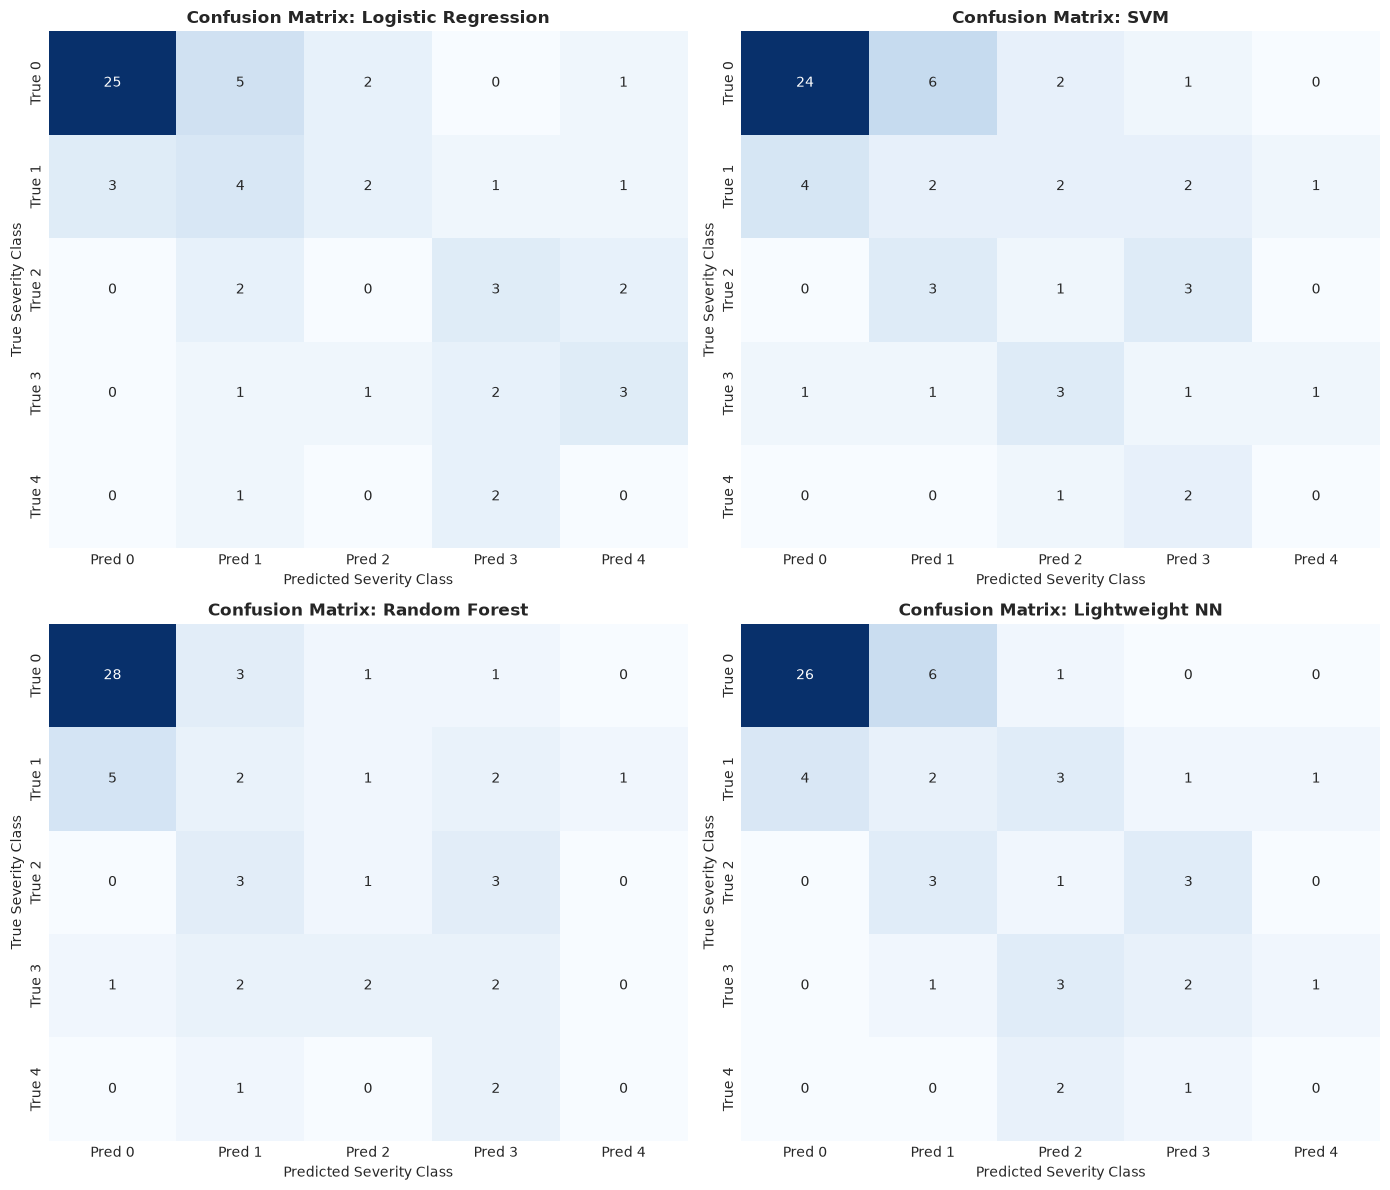

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test_final, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[f'Pred {i}' for i in range(5)],
        yticklabels=[f'True {i}' for i in range(5)],
        ax=ax,
        cbar=False
    )
    ax.set_title(f'Confusion Matrix: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Severity Class')
    ax.set_ylabel('True Severity Class')

plt.tight_layout()
plt.show()

## 7. Multi-Class One-vs-Rest ROC Curves
Plotting ROC curves for each severity class across all 4 models.

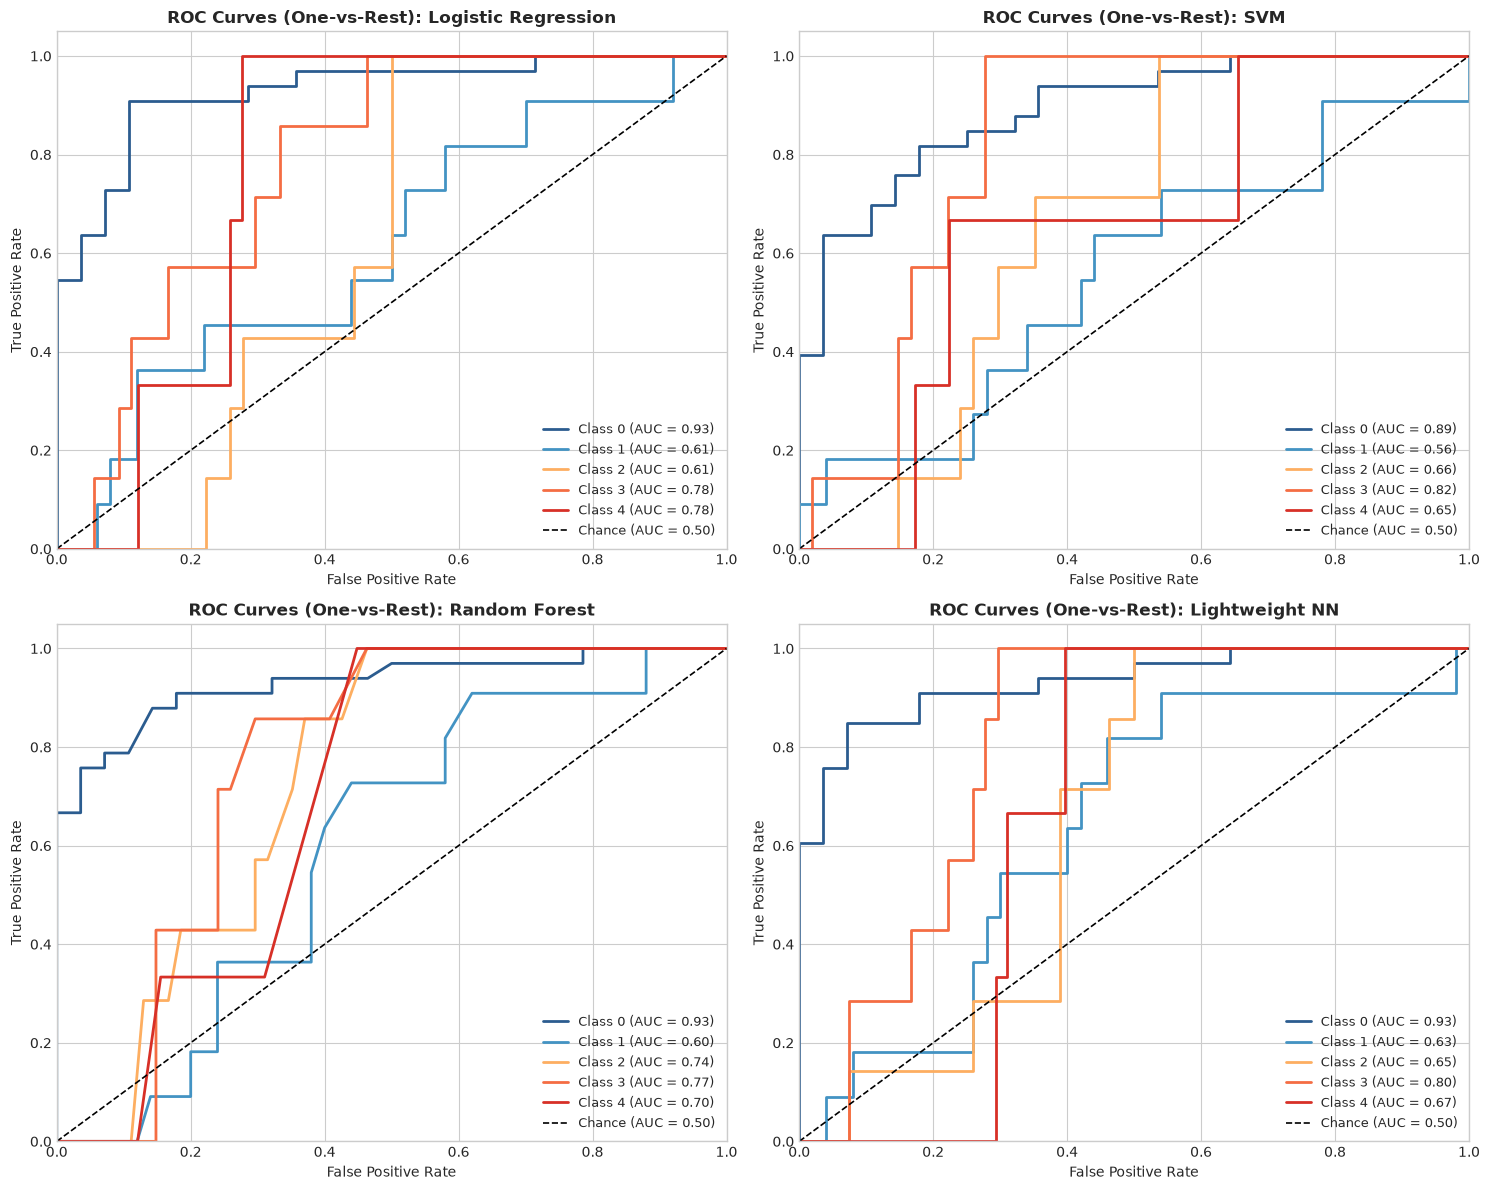

In [8]:
# Binarize test labels for One-vs-Rest ROC curve plotting
y_test_bin = label_binarize(y_test_final, classes=[0, 1, 2, 3, 4])
n_classes = 5

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
colors = ['#2b5c8f', '#4393c3', '#fdae61', '#f46d43', '#d73027']

for idx, (name, prob) in enumerate(probabilities.items()):
    ax = axes[idx]
    
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], prob[:, i])
        roc_auc_val = auc(fpr, tpr)
        ax.plot(
            fpr, tpr,
            color=colors[i],
            lw=2,
            label=f'Class {i} (AUC = {roc_auc_val:.2f})'
        )
        
    ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Chance (AUC = 0.50)')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate', fontsize=10)
    ax.set_ylabel('True Positive Rate', fontsize=10)
    ax.set_title(f'ROC Curves (One-vs-Rest): {name}', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

## 8. Comparative Results Dashboard
Comparing overall performance metrics across all 4 classifiers.

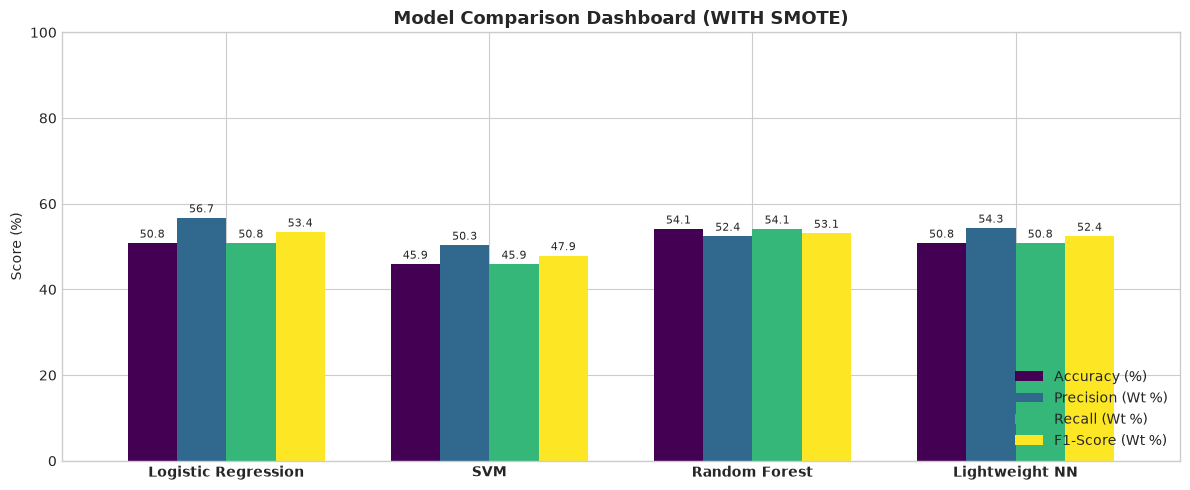

In [9]:
title_suffix = 'WITH SMOTE'
fig, ax = plt.subplots(figsize=(12, 5))

metrics_plot_df = metrics_df.set_index('Model')[['Accuracy (%)', 'Precision (Wt %)', 'Recall (Wt %)', 'F1-Score (Wt %)']]
metrics_plot_df.plot(kind='bar', ax=ax, colormap='viridis', width=0.75)

ax.set_title(f'Model Comparison Dashboard ({title_suffix})', fontsize=13, fontweight='bold')
ax.set_ylabel('Score (%)')
ax.set_xlabel('')
ax.set_ylim(0, 100)
ax.legend(loc='lower right')
plt.xticks(rotation=0, fontweight='bold')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()